In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import pickle
from pathlib import Path

# Load the temporal networks created in Notebook 2
save_path = Path("../Data/Cleaned/temporal_networks.pkl")

with save_path.open("rb") as file:
    networks_by_time = pickle.load(file)

print("Number of timestamps:", len(networks_by_time))

Number of timestamps: 7375


In [2]:
BETA = 0.02                 # Probability of transmission per contact
DT = 24 * 3600              # Infectious period: 24 hours
N_REPS = 100                # Number of SIR simulations per condition
COVERAGES = [0.1, 0.2, 0.3, 0.4, 0.5]

HORIZON_HOURS = 2           # Time allowed for reachability
N_STARTS = 5                # Starting timestamps sampled per student

rng = np.random.default_rng(42)

In [3]:
# Get every student who appears in at least one network snapshot
ids = np.array(
    sorted(set().union(
        *[set(G.nodes) for G in networks_by_time.values()]
    ))
)

N = len(ids)

# Store timestamps in chronological order
ts = np.array(sorted(networks_by_time))

print("Number of students:", N)
print("Number of timestamps:", len(ts))

Number of students: 327
Number of timestamps: 7375


In [4]:
# Create empty lists for the contacts
t_list = []
i_list = []
j_list = []

# Go through every timestamp and every interaction
for t in ts:
    for u, v in networks_by_time[t].edges():

        t_list.append(t)
        i_list.append(u)
        j_list.append(v)

# Convert lists into NumPy arrays
t_arr = np.array(t_list)

# Convert student IDs into array positions
i_arr = np.searchsorted(ids, i_list)
j_arr = np.searchsorted(ids, j_list)

# Find where the contacts for each timestamp begin and end
bounds = np.append(
    np.searchsorted(t_arr, ts),
    len(t_arr)
)

print("Students:", N)
print("Timestamps:", len(ts))
print("Total contacts:", len(t_arr))

Students: 327
Timestamps: 7375
Total contacts: 188508


In [5]:
# Count each student's total connections across all timestamps
degree_sum = (
    np.bincount(i_arr, minlength=N)
    + np.bincount(j_arr, minlength=N)
)

# Divide by the total number of timestamps
# This gives the average degree per timestamp
temporal_degree = degree_sum / len(ts)

# Create a table with each student's temporal degree
degree_table = pl.DataFrame({
    "student": ids,
    "temporal_degree": temporal_degree
}).sort("temporal_degree", descending=True)

print(degree_table)

# Display summary statistics
print(degree_table.describe())

shape: (327, 2)
┌─────────┬─────────────────┐
│ student ┆ temporal_degree │
│ ---     ┆ ---             │
│ i64     ┆ f64             │
╞═════════╪═════════════════╡
│ 884     ┆ 0.630102        │
│ 1359    ┆ 0.588203        │
│ 513     ┆ 0.573695        │
│ 255     ┆ 0.560814        │
│ 122     ┆ 0.556339        │
│ …       ┆ …               │
│ 103     ┆ 0.005831        │
│ 165     ┆ 0.004475        │
│ 681     ┆ 0.003661        │
│ 62      ┆ 0.00122         │
│ 434     ┆ 0.000949        │
└─────────┴─────────────────┘
shape: (9, 3)
┌────────────┬────────────┬─────────────────┐
│ statistic  ┆ student    ┆ temporal_degree │
│ ---        ┆ ---        ┆ ---             │
│ str        ┆ f64        ┆ f64             │
╞════════════╪════════════╪═════════════════╡
│ count      ┆ 327.0      ┆ 327.0           │
│ null_count ┆ 0.0        ┆ 0.0             │
│ mean       ┆ 549.036697 ┆ 0.156333        │
│ std        ┆ 419.063034 ┆ 0.119178        │
│ min        ┆ 1.0        ┆ 0.000949        │


In [6]:
top = np.argsort(-temporal_degree)[:5]

print("Top 5 students by temporal degree:")

for rank, k in enumerate(top, start=1):
    print(
        f"{rank}. Student {ids[k]}: "
        f"{temporal_degree[k]:.3f}"
    )

Top 5 students by temporal degree:
1. Student 884: 0.630
2. Student 1359: 0.588
3. Student 513: 0.574
4. Student 255: 0.561
5. Student 122: 0.556


In [7]:
def sir(immune, seed, k0, beta, dt, rng, horizon=np.inf):

    # Record the infection time for each student
    # Infinity means the student has not been infected
    inf = np.full(N, np.inf)

    # Identify students who are immunized
    blocked = np.zeros(N, dtype=bool)
    blocked[np.asarray(immune, dtype=int)] = True

    # Infect the initial seed just before the starting timestamp
    inf[seed] = ts[k0] - 20

    # Track the time of the most recent infection
    last = ts[k0]

    # Move through the timestamps chronologically
    for k in range(k0, len(ts)):

        t = ts[k]

        # Stop if the outbreak has gone longer than the infectious
        # period without a new infection, or if the horizon is reached
        if t - last > dt or t - ts[k0] > horizon:
            break

        # Get all contacts at the current timestamp
        a = i_arr[bounds[k]:bounds[k+1]]
        b = j_arr[bounds[k]:bounds[k+1]]

        new = []

        # Check transmission in both directions
        for u, v in ((a, b), (b, a)):

            # Check whether u is currently infectious
            can_pass = (
                (inf[u] < t)
                & (t - inf[u] <= dt)
            )

            # Check whether v has never been infected and is not immune
            can_catch = (
                np.isinf(inf[v])
                & ~blocked[v]
            )

            # Randomly determine whether transmission occurs
            hit = (
                can_pass
                & can_catch
                & (rng.random(len(u)) < beta)
            )

            new.append(v[hit])

        # Combine newly infected students and remove duplicates
        new = np.unique(np.concatenate(new))

        # Record the new infections
        if len(new) > 0:
            inf[new] = t
            last = t

    # Return the total number of students infected
    return int(np.isfinite(inf).sum())

In [8]:
# Find the timestamp index at the end of the first 24 hours
DAY1_END = np.searchsorted(
    ts,
    ts[0] + 24 * 3600
)

print("Timestamps available during day 1:", DAY1_END)

Timestamps available during day 1: 1619


In [9]:
def draw_start_and_seed(immune, rng):

    while True:

        # Select a random timestamp during the first day
        k0 = rng.integers(0, DAY1_END)

        # Find students involved in contacts at that timestamp
        present = np.unique(
            np.concatenate([
                i_arr[bounds[k0]:bounds[k0+1]],
                j_arr[bounds[k0]:bounds[k0+1]]
            ])
        )

        # Remove students who are immunized
        candidates = np.setdiff1d(present, immune)

        # Select a seed from the remaining students
        if len(candidates) > 0:
            seed = rng.choice(candidates)
            return k0, seed

In [10]:
# Identify the timestamp index associated with each contact
ev_k = np.repeat(
    np.arange(len(ts)),
    np.diff(bounds)
)

print("Number of contact timestamp labels:", len(ev_k))
print("Number of contacts:", len(t_arr))

Number of contact timestamp labels: 188508
Number of contacts: 188508


In [11]:
def compute_reachability(horizon, n_starts, rng):

    # Create one reachability score for each student
    score = np.zeros(N)

    # Calculate reachability for every student
    for n in range(N):

        # Find all contacts involving this student
        rows_n = np.where(
            (i_arr == n) | (j_arr == n)
        )[0]

        # Find the timestamps when this student had contacts
        starts = np.unique(ev_k[rows_n])

        # Only use starting timestamps from day 1
        starts = starts[starts < DAY1_END]

        # If the student had no contacts during day 1, leave score at 0
        if len(starts) == 0:
            continue

        # Randomly select starting timestamps
        chosen = rng.choice(
            starts,
            min(n_starts, len(starts)),
            replace=False
        )

        # Run the temporal network from each selected starting time
        # beta = 1.0 means every eligible contact transmits
        # subtract 1 to exclude the original seed student
        reached = []

        for k in chosen:

            number_infected = sir(
                immune=[],
                seed=n,
                k0=k,
                beta=1.0,
                dt=DT,
                rng=rng,
                horizon=horizon
            )

            reached.append(number_infected - 1)

        # Average the number of other students reached
        score[n] = np.mean(reached)

    return score

In [12]:
# Calculate reachability using the selected two-hour horizon
reachability = compute_reachability(
    horizon=HORIZON_HOURS * 3600,
    n_starts=N_STARTS,
    rng=rng
)

print(
    "Reachability min / median / max:",
    reachability.min(),
    np.median(reachability),
    reachability.max()
)

Reachability min / median / max: 0.0 131.6 282.8


In [13]:
reachability_table = pl.DataFrame({
    "student": ids,
    "reachability": reachability
}).sort("reachability", descending=True)

print(reachability_table)

shape: (327, 2)
┌─────────┬──────────────┐
│ student ┆ reachability │
│ ---     ┆ ---          │
│ i64     ┆ f64          │
╞═════════╪══════════════╡
│ 171     ┆ 282.8        │
│ 797     ┆ 276.8        │
│ 311     ┆ 275.0        │
│ 751     ┆ 268.6        │
│ 694     ┆ 265.4        │
│ …       ┆ …            │
│ 941     ┆ 3.0          │
│ 62      ┆ 0.0          │
│ 239     ┆ 0.0          │
│ 445     ┆ 0.0          │
│ 452     ┆ 0.0          │
└─────────┴──────────────┘


In [14]:
top = np.argsort(-reachability)[:5]

print("Top 5 students by temporal reachability:")

for rank, k in enumerate(top, start=1):
    print(
        f"{rank}. Student {ids[k]}: "
        f"{reachability[k]:.2f}"
    )

Top 5 students by temporal reachability:
1. Student 171: 282.80
2. Student 797: 276.80
3. Student 311: 275.00
4. Student 751: 268.60
5. Student 694: 265.40


In [15]:
measure_table = pl.DataFrame({
    "student": ids,
    "temporal_degree": temporal_degree,
    "reachability": reachability
}).sort("temporal_degree", descending=True)

print(measure_table)

shape: (327, 3)
┌─────────┬─────────────────┬──────────────┐
│ student ┆ temporal_degree ┆ reachability │
│ ---     ┆ ---             ┆ ---          │
│ i64     ┆ f64             ┆ f64          │
╞═════════╪═════════════════╪══════════════╡
│ 884     ┆ 0.630102        ┆ 125.8        │
│ 1359    ┆ 0.588203        ┆ 206.8        │
│ 513     ┆ 0.573695        ┆ 201.2        │
│ 255     ┆ 0.560814        ┆ 149.0        │
│ 122     ┆ 0.556339        ┆ 103.2        │
│ …       ┆ …               ┆ …            │
│ 103     ┆ 0.005831        ┆ 185.4        │
│ 165     ┆ 0.004475        ┆ 106.0        │
│ 681     ┆ 0.003661        ┆ 57.4         │
│ 62      ┆ 0.00122         ┆ 0.0          │
│ 434     ┆ 0.000949        ┆ 13.0         │
└─────────┴─────────────────┴──────────────┘


In [16]:
baseline = []

for rep in range(N_REPS):

    # Select a random starting time and seed
    k0, seed = draw_start_and_seed([], rng)

    # Run the SIR simulation without immunization
    outbreak_size = sir(
        immune=[],
        seed=seed,
        k0=k0,
        beta=BETA,
        dt=DT,
        rng=rng
    )

    baseline.append(outbreak_size)

print(
    "Mean baseline outbreak size:",
    np.mean(baseline)
)

print(
    "Mean baseline share infected:",
    round(np.mean(baseline) / N, 3)
)

Mean baseline outbreak size: 153.86
Mean baseline share infected: 0.471


In [17]:
def top_k(scores, k, rng):

    # Randomize the order to break ties
    perm = rng.permutation(N)

    # Sort students by score, highest first
    ordered = perm[
        np.argsort(-scores[perm], kind="stable")
    ]

    # Return the top k students
    return ordered[:k]

In [18]:
scores = {
    "temporal_degree": temporal_degree,
    "reachability": reachability
}

strategies = [
    "random",
    "temporal_degree",
    "reachability"
]

In [19]:
rows = []

# Test each immunization coverage level
for cov in COVERAGES:

    # Calculate how many students will be immunized
    k = int(round(cov * N))

    # Test each immunization strategy
    for strat in strategies:

        # Repeat each condition 100 times
        for rep in range(N_REPS):

            # Random immunization
            if strat == "random":
                immune = rng.choice(
                    N,
                    k,
                    replace=False
                )

            # Targeted immunization
            else:
                immune = top_k(
                    scores[strat],
                    k,
                    rng
                )

            # Select a starting time and non-immunized seed
            k0, seed = draw_start_and_seed(
                immune,
                rng
            )

            # Run the SIR model
            outbreak_size = sir(
                immune=immune,
                seed=seed,
                k0=k0,
                beta=BETA,
                dt=DT,
                rng=rng
            )

            # Save the results
            rows.append((
                strat,
                cov,
                rep,
                outbreak_size
            ))

print("Total simulations:", len(rows))

Total simulations: 1500


In [20]:
results = pl.DataFrame(
    rows,
    schema=[
        "strategy",
        "coverage",
        "rep",
        "size"
    ],
    orient="row"
)

print(results)

shape: (1_500, 4)
┌──────────────┬──────────┬─────┬──────┐
│ strategy     ┆ coverage ┆ rep ┆ size │
│ ---          ┆ ---      ┆ --- ┆ ---  │
│ str          ┆ f64      ┆ i64 ┆ i64  │
╞══════════════╪══════════╪═════╪══════╡
│ random       ┆ 0.1      ┆ 0   ┆ 103  │
│ random       ┆ 0.1      ┆ 1   ┆ 75   │
│ random       ┆ 0.1      ┆ 2   ┆ 108  │
│ random       ┆ 0.1      ┆ 3   ┆ 137  │
│ random       ┆ 0.1      ┆ 4   ┆ 67   │
│ …            ┆ …        ┆ …   ┆ …    │
│ reachability ┆ 0.5      ┆ 95  ┆ 3    │
│ reachability ┆ 0.5      ┆ 96  ┆ 10   │
│ reachability ┆ 0.5      ┆ 97  ┆ 1    │
│ reachability ┆ 0.5      ┆ 98  ┆ 23   │
│ reachability ┆ 0.5      ┆ 99  ┆ 3    │
└──────────────┴──────────┴─────┴──────┘


In [21]:
summary = (
    results
    .group_by(["strategy", "coverage"])
    .agg(
        mean=pl.col("size").mean(),
        sd=pl.col("size").std()
    )
    .sort(["strategy", "coverage"])
)

print(summary)

shape: (15, 4)
┌─────────────────┬──────────┬────────┬───────────┐
│ strategy        ┆ coverage ┆ mean   ┆ sd        │
│ ---             ┆ ---      ┆ ---    ┆ ---       │
│ str             ┆ f64      ┆ f64    ┆ f64       │
╞═════════════════╪══════════╪════════╪═══════════╡
│ random          ┆ 0.1      ┆ 103.98 ┆ 60.042406 │
│ random          ┆ 0.2      ┆ 74.11  ┆ 43.740256 │
│ random          ┆ 0.3      ┆ 39.1   ┆ 31.844794 │
│ random          ┆ 0.4      ┆ 21.25  ┆ 19.825183 │
│ random          ┆ 0.5      ┆ 10.88  ┆ 11.460322 │
│ …               ┆ …        ┆ …      ┆ …         │
│ temporal_degree ┆ 0.1      ┆ 59.77  ┆ 41.284882 │
│ temporal_degree ┆ 0.2      ┆ 28.66  ┆ 27.22418  │
│ temporal_degree ┆ 0.3      ┆ 12.8   ┆ 14.485102 │
│ temporal_degree ┆ 0.4      ┆ 3.84   ┆ 3.90731   │
│ temporal_degree ┆ 0.5      ┆ 3.11   ┆ 3.553047  │
└─────────────────┴──────────┴────────┴───────────┘


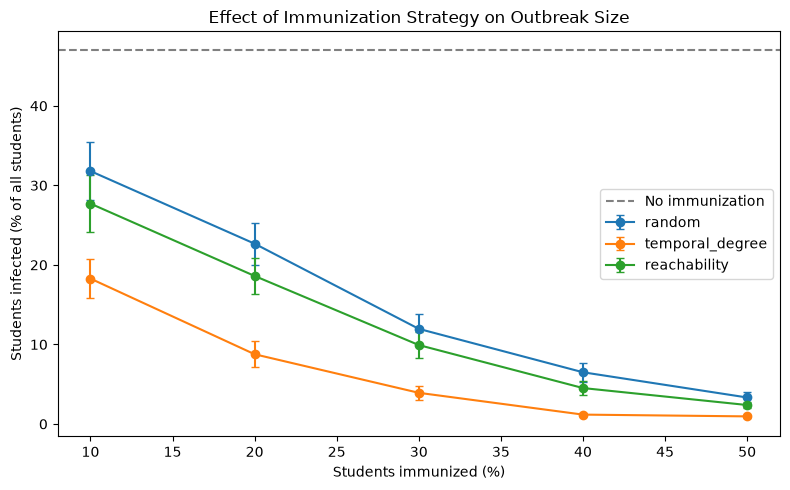

In [22]:
plt.figure(figsize=(8, 5))

for strat in strategies:

    # Select results for the current strategy
    s = summary.filter(
        pl.col("strategy") == strat
    )

    # Convert outbreak sizes to percentage of students
    mean_percent = (
        s["mean"].to_numpy() / N
    ) * 100

    # Calculate approximate 95% confidence intervals
    error = (
        1.96
        * s["sd"].to_numpy()
        / np.sqrt(N_REPS)
        / N
        * 100
    )

    # Plot the strategy
    plt.errorbar(
        s["coverage"].to_numpy() * 100,
        mean_percent,
        yerr=error,
        marker="o",
        capsize=3,
        label=strat
    )

# Add the baseline outbreak size
plt.axhline(
    np.mean(baseline) / N * 100,
    linestyle="--",
    color="gray",
    label="No immunization"
)

plt.xlabel("Students immunized (%)")
plt.ylabel("Students infected (% of all students)")
plt.title("Effect of Immunization Strategy on Outbreak Size")

plt.legend()
plt.tight_layout()
plt.show()